# Lab 3: AI Programming Frameworks and Data Preparation
## Notebook 2: Exploratory Data Analysis and Visualization

### Objectives:
Perform comprehensive Exploratory Data Analysis (EDA) on two benchmark datasets using **Pandas**, **NumPy**, **Matplotlib**, and **Seaborn**:

#### 1. Campus Placement Dataset:
- Placement status distribution
- Academic percentage distributions (`ssc_p`, `hsc_p`, `degree_p`, `etest_p`, `mba_p`)
- Work experience distribution and its effect on placement
- MBA Specialization analysis
- Salary distribution for placed students
- Placement status comparisons across academic scores
- Inter-feature correlation heatmap

#### 2. Bank Marketing Dataset:
- Customer age distribution
- Job category distribution
- Marital status distribution
- Account balance distribution
- Marketing campaign outcomes (`poutcome` and subscription `y`)
- Subscription rate comparisons across demographics

*All generated visualization artifacts are exported to `Lab3/outputs/`.*

In [1]:
# 1. Essential Library Imports and Configuration
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10

# Dynamic relative paths (runs from repository root or Lab3 directory)
DATA_DIR = Path("datasets") if Path("datasets").exists() else Path("../datasets")
OUTPUT_DIR = Path("Lab3/outputs") if Path("Lab3").exists() else Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Data Directory  : {DATA_DIR.resolve()}")
print(f"Output Directory: {OUTPUT_DIR.resolve()}")

Data Directory  : /home/jeet/Desktop/Artificial_Intelligence/datasets
Output Directory: /home/jeet/Desktop/Artificial_Intelligence/Lab3/outputs


In [2]:
# 2. Loading Datasets with Missing File Verification
placement_file = DATA_DIR / "Placement_Data_Full_Class.csv"
bank_file = DATA_DIR / "bank-full.csv"

# Verify existence
for path in [placement_file, bank_file]:
    if not path.exists():
        raise FileNotFoundError(f"Missing required dataset: {path}")

# Load Campus Placement dataset
df_placement = pd.read_csv(placement_file)
print(f"Loaded Placement Dataset: {df_placement.shape[0]} rows, {df_placement.shape[1]} columns")

# Load Bank Marketing dataset (semicolon-delimited)
df_bank = pd.read_csv(bank_file, sep=';')
print(f"Loaded Bank Marketing Dataset: {df_bank.shape[0]} rows, {df_bank.shape[1]} columns")

Loaded Placement Dataset: 215 rows, 15 columns
Loaded Bank Marketing Dataset: 45211 rows, 17 columns


findfont: Failed to find font weight semibold for Liberation Sans, now using 700.


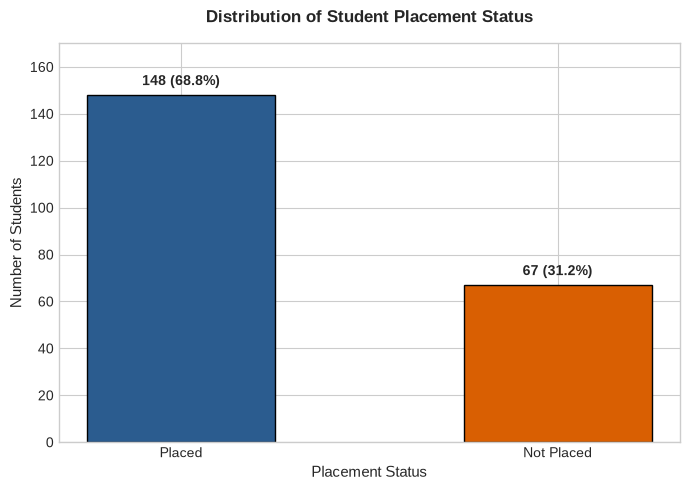

Saved plot: Lab3/outputs/placement_status_distribution.png


In [3]:
# 3. Placement Status Distribution
fig, ax = plt.subplots(figsize=(7, 5))
status_counts = df_placement['status'].value_counts()
colors = ['#2b5c8f', '#d95f02']

bars = ax.bar(status_counts.index, status_counts.values, color=colors, width=0.5, edgecolor='black')
ax.set_title("Distribution of Student Placement Status", fontweight='bold', pad=15)
ax.set_xlabel("Placement Status")
ax.set_ylabel("Number of Students")
ax.set_ylim(0, max(status_counts.values) * 1.15)

# Annotate counts and percentages
for bar in bars:
    height = bar.get_height()
    pct = (height / len(df_placement)) * 100
    ax.annotate(f"{height} ({pct:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha='center', va='bottom', fontweight='semibold')

plt.tight_layout()
fig_path = OUTPUT_DIR / "placement_status_distribution.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved plot: {fig_path}")

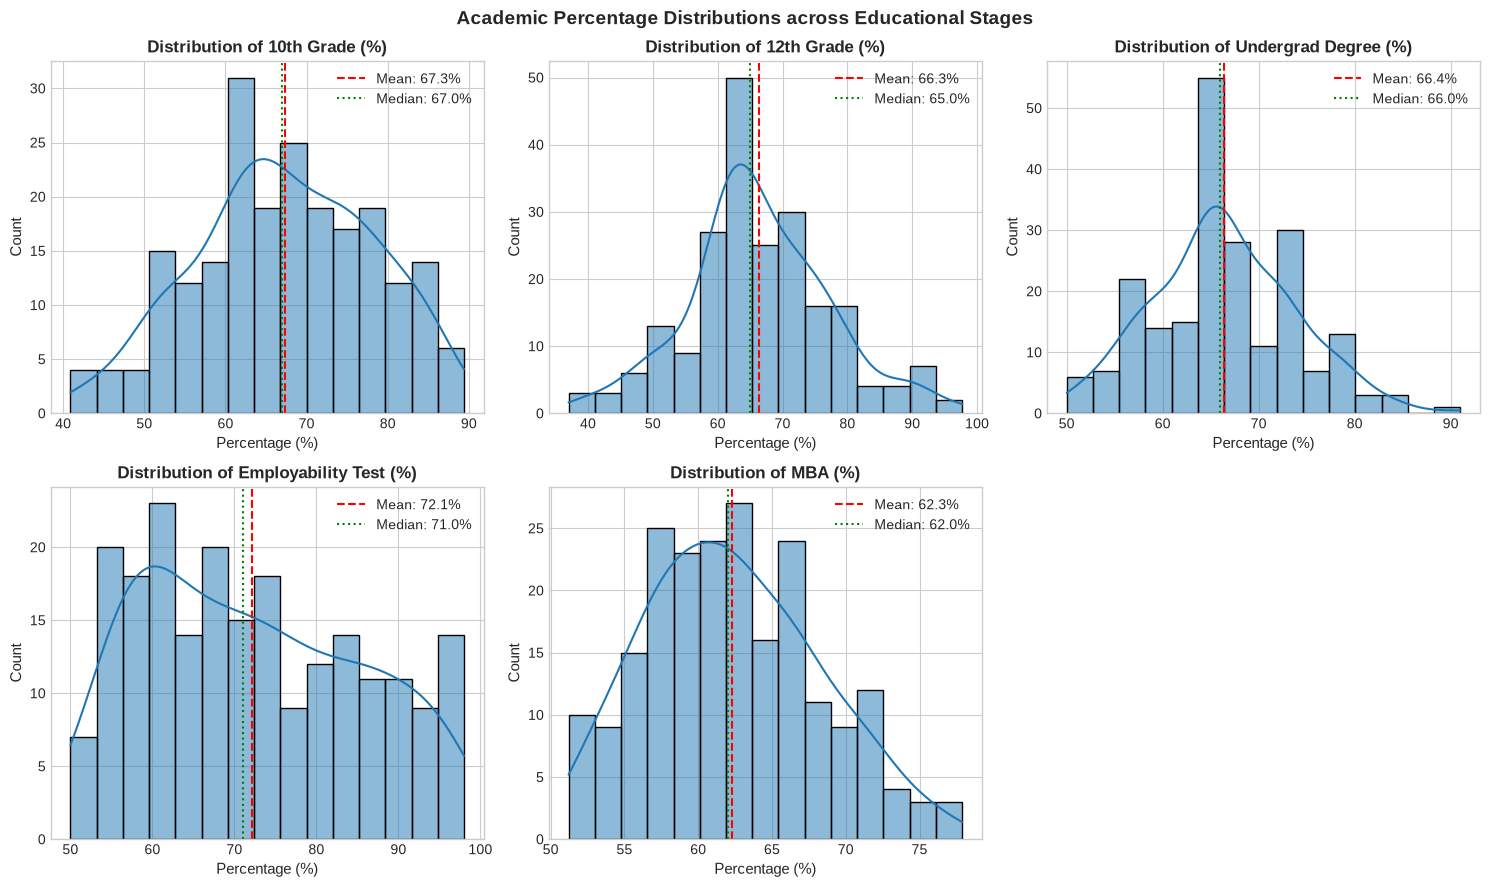

Saved plot: Lab3/outputs/academic_percentages_distribution.png


In [4]:
# 4. Academic Percentage Distributions across Academic Tiers
score_columns = ['ssc_p', 'hsc_p', 'degree_p', 'etest_p', 'mba_p']
score_labels = ['10th Grade (%)', '12th Grade (%)', 'Undergrad Degree (%)', 'Employability Test (%)', 'MBA (%)']

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (col, label) in enumerate(zip(score_columns, score_labels)):
    ax = axes[i]
    sns.histplot(df_placement[col], kde=True, ax=ax, color='#1f77b4', bins=15, edgecolor='black')
    mean_val = df_placement[col].mean()
    median_val = df_placement[col].median()
    ax.axvline(mean_val, color='red', linestyle='--', linewidth=1.5, label=f"Mean: {mean_val:.1f}%")
    ax.axvline(median_val, color='green', linestyle=':', linewidth=1.5, label=f"Median: {median_val:.1f}%")
    ax.set_title(f"Distribution of {label}", fontweight='bold')
    ax.set_xlabel("Percentage (%)")
    ax.set_ylabel("Count")
    ax.legend()

# Remove unused 6th subplot
fig.delaxes(axes[5])
plt.suptitle("Academic Percentage Distributions across Educational Stages", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path = OUTPUT_DIR / "academic_percentages_distribution.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved plot: {fig_path}")

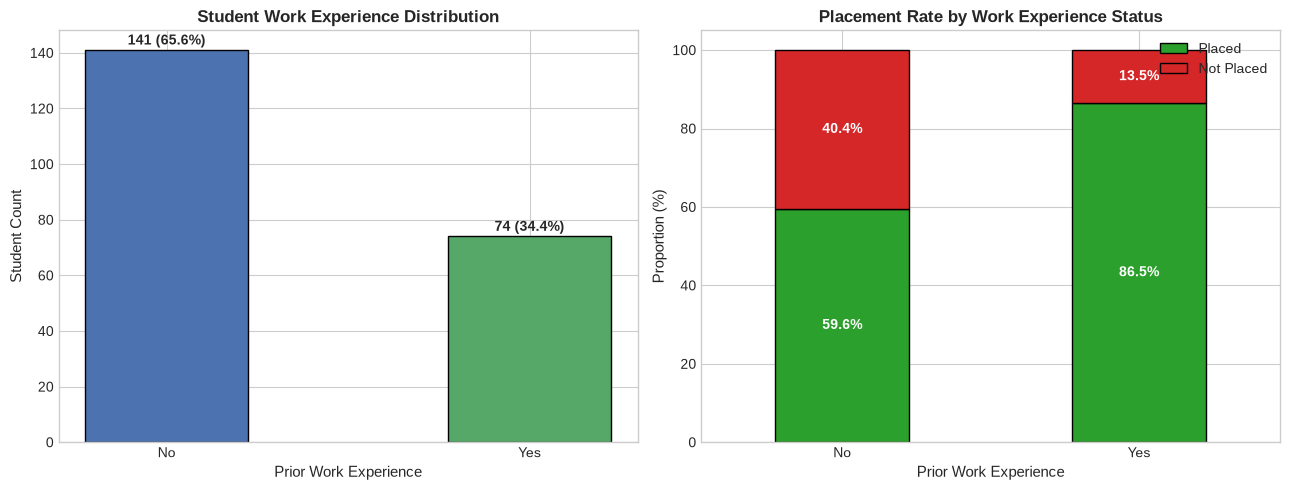

Saved plot: Lab3/outputs/workex_placement_analysis.png


In [5]:
# 5. Work Experience Distribution and Placement Rate
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Count of students with/without work experience
workex_counts = df_placement['workex'].value_counts()
ax1.bar(workex_counts.index, workex_counts.values, color=['#4c72b0', '#55a868'], edgecolor='black', width=0.45)
ax1.set_title("Student Work Experience Distribution", fontweight='bold')
ax1.set_xlabel("Prior Work Experience")
ax1.set_ylabel("Student Count")
for idx, val in enumerate(workex_counts.values):
    ax1.text(idx, val + 2, f"{val} ({val/len(df_placement)*100:.1f}%)", ha='center', fontweight='semibold')

# Plot 2: Placement Rate by Work Experience
workex_placement = pd.crosstab(df_placement['workex'], df_placement['status'], normalize='index') * 100
workex_placement[['Placed', 'Not Placed']].plot(kind='bar', stacked=True, color=['#2ca02c', '#d62728'],
                                                ax=ax2, edgecolor='black', width=0.45)
ax2.set_title("Placement Rate by Work Experience Status", fontweight='bold')
ax2.set_xlabel("Prior Work Experience")
ax2.set_ylabel("Proportion (%)")
ax2.legend(["Placed", "Not Placed"], loc='upper right')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=0)

for p in ax2.patches:
    height = p.get_height()
    if height > 5:
        ax2.annotate(f"{height:.1f}%",
                    (p.get_x() + p.get_width() / 2, p.get_y() + height / 2),
                    ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
fig_path = OUTPUT_DIR / "workex_placement_analysis.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved plot: {fig_path}")

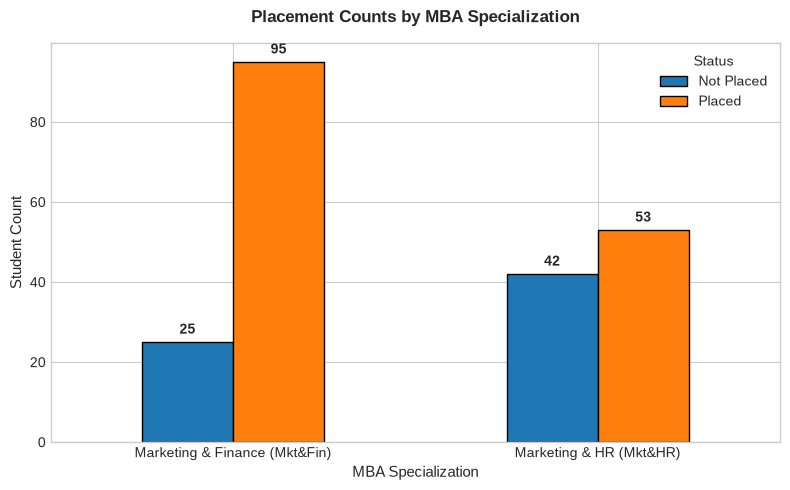

Saved plot: Lab3/outputs/specialization_placement_analysis.png


In [6]:
# 6. MBA Specialization Analysis
fig, ax = plt.subplots(figsize=(8, 5))

spec_crosstab = pd.crosstab(df_placement['specialisation'], df_placement['status'])
spec_crosstab.plot(kind='bar', ax=ax, color=['#1f77b4', '#ff7f0e'], edgecolor='black', width=0.5)

ax.set_title("Placement Counts by MBA Specialization", fontweight='bold', pad=15)
ax.set_xlabel("MBA Specialization")
ax.set_ylabel("Student Count")
ax.set_xticklabels(['Marketing & Finance (Mkt&Fin)', 'Marketing & HR (Mkt&HR)'], rotation=0)
ax.legend(["Not Placed", "Placed"], title="Status")

for p in ax.patches:
    val = int(p.get_height())
    if val > 0:
        ax.annotate(f"{val}",
                    (p.get_x() + p.get_width() / 2, p.get_height()),
                    xytext=(0, 4), textcoords="offset points",
                    ha='center', va='bottom', fontweight='semibold')

plt.tight_layout()
fig_path = OUTPUT_DIR / "specialization_placement_analysis.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved plot: {fig_path}")

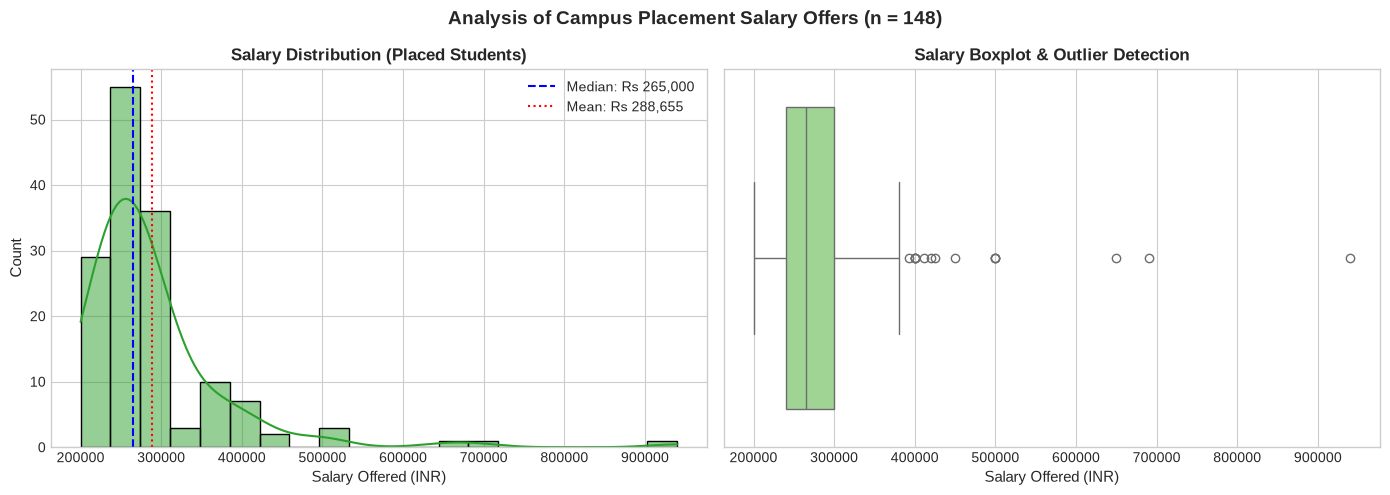

Saved plot: Lab3/outputs/salary_distribution_placed.png


In [7]:
# 7. Salary Distribution for Placed Students
placed_df = df_placement[df_placement['status'] == 'Placed'].dropna(subset=['salary'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with KDE
sns.histplot(placed_df['salary'], kde=True, ax=ax1, color='#2ca02c', bins=20, edgecolor='black')
median_sal = placed_df['salary'].median()
mean_sal = placed_df['salary'].mean()
ax1.axvline(median_sal, color='blue', linestyle='--', linewidth=1.5, label=f"Median: Rs {median_sal:,.0f}")
ax1.axvline(mean_sal, color='red', linestyle=':', linewidth=1.5, label=f"Mean: Rs {mean_sal:,.0f}")
ax1.set_title("Salary Distribution (Placed Students)", fontweight='bold')
ax1.set_xlabel("Salary Offered (INR)")
ax1.set_ylabel("Count")
ax1.legend()

# Boxplot highlighting outliers
sns.boxplot(x=placed_df['salary'], ax=ax2, color='#98df8a')
ax2.set_title("Salary Boxplot & Outlier Detection", fontweight='bold')
ax2.set_xlabel("Salary Offered (INR)")

plt.suptitle(f"Analysis of Campus Placement Salary Offers (n = {len(placed_df)})", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path = OUTPUT_DIR / "salary_distribution_placed.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved plot: {fig_path}")

/tmp/ipykernel_476014/1311749276.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='status', y=var, data=df_placement, ax=ax, palette=['#1f77b4', '#ff7f0e'])
/tmp/ipykernel_476014/1311749276.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='status', y=var, data=df_placement, ax=ax, palette=['#1f77b4', '#ff7f0e'])
/tmp/ipykernel_476014/1311749276.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='status', y=var, data=df_placement, ax=ax, palette=['#1f77b4', '#ff7f0e'])


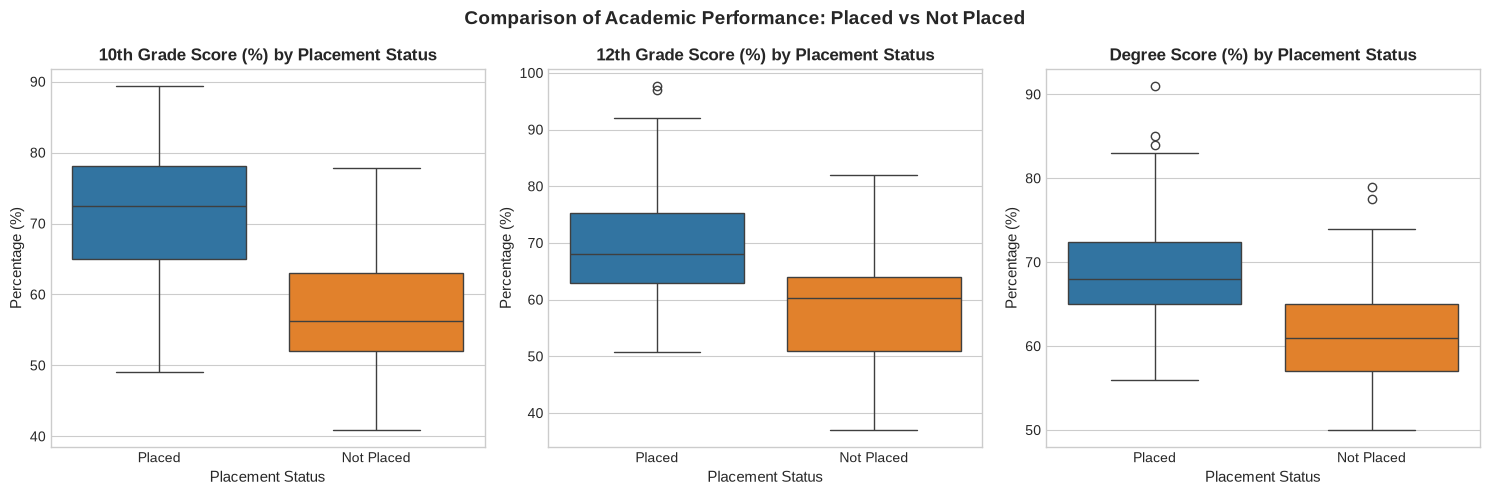

Saved plot: Lab3/outputs/academic_scores_vs_placement.png


In [8]:
# 8. Placement Status Comparisons across Academic Stages
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

score_vars = ['ssc_p', 'hsc_p', 'degree_p']
score_names = ['10th Grade Score (%)', '12th Grade Score (%)', 'Degree Score (%)']

for ax, var, name in zip(axes, score_vars, score_names):
    sns.boxplot(x='status', y=var, data=df_placement, ax=ax, palette=['#1f77b4', '#ff7f0e'])
    ax.set_title(f"{name} by Placement Status", fontweight='bold')
    ax.set_xlabel("Placement Status")
    ax.set_ylabel("Percentage (%)")

plt.suptitle("Comparison of Academic Performance: Placed vs Not Placed", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path = OUTPUT_DIR / "academic_scores_vs_placement.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved plot: {fig_path}")

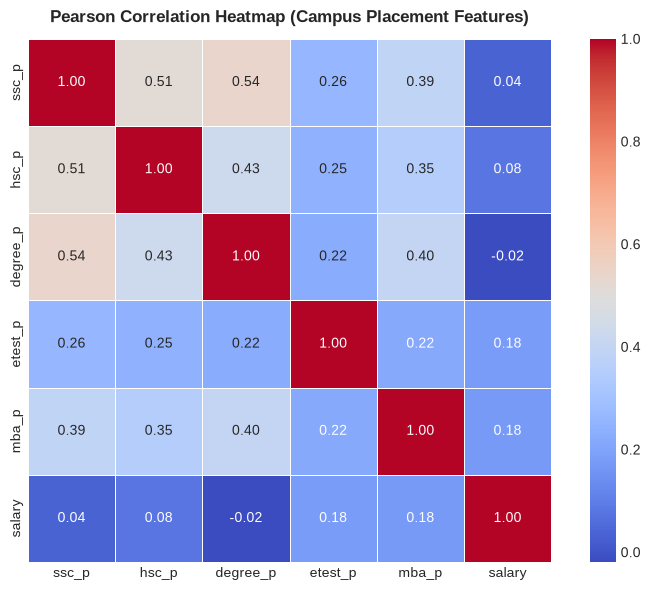

Saved plot: Lab3/outputs/placement_correlation_heatmap.png


In [9]:
# 9. Correlation Heatmap of Campus Placement Numerical Features
numerical_cols = ['ssc_p', 'hsc_p', 'degree_p', 'etest_p', 'mba_p', 'salary']
corr_matrix = df_placement[numerical_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True,
            linewidths=0.5, linecolor='white', square=True, ax=ax)
ax.set_title("Pearson Correlation Heatmap (Campus Placement Features)", fontweight='bold', pad=12)

plt.tight_layout()
fig_path = OUTPUT_DIR / "placement_correlation_heatmap.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved plot: {fig_path}")

In [10]:
# 10. Bank Marketing Dataset Overview
print("--- Bank Marketing Dataset Head ---")
display(df_bank.head(3))
print("--- Bank Marketing Dimensions ---")
print(f"Rows: {df_bank.shape[0]}, Columns: {df_bank.shape[1]}")
print("--- Target Variable 'y' Distribution ---")
display(df_bank['y'].value_counts(normalize=True).round(3) * 100)

--- Bank Marketing Dataset Head ---


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no


--- Bank Marketing Dimensions ---
Rows: 45211, Columns: 17
--- Target Variable 'y' Distribution ---


y
no     88.3
yes    11.7
Name: proportion, dtype: float64

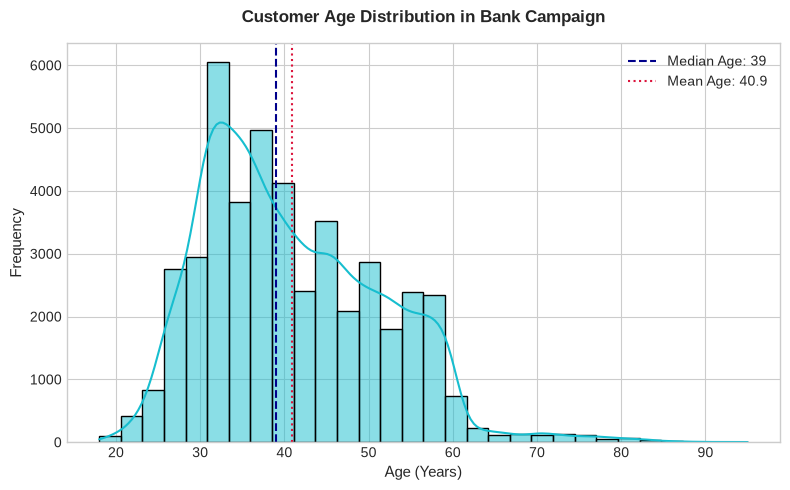

Saved plot: Lab3/outputs/bank_age_distribution.png


In [11]:
# 11. Customer Age Distribution (Bank Marketing)
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(df_bank['age'], bins=30, kde=True, ax=ax, color='#17becf', edgecolor='black')
median_age = df_bank['age'].median()
mean_age = df_bank['age'].mean()
ax.axvline(median_age, color='darkblue', linestyle='--', linewidth=1.5, label=f"Median Age: {median_age:.0f}")
ax.axvline(mean_age, color='crimson', linestyle=':', linewidth=1.5, label=f"Mean Age: {mean_age:.1f}")

ax.set_title("Customer Age Distribution in Bank Campaign", fontweight='bold', pad=15)
ax.set_xlabel("Age (Years)")
ax.set_ylabel("Frequency")
ax.legend()

plt.tight_layout()
fig_path = OUTPUT_DIR / "bank_age_distribution.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved plot: {fig_path}")

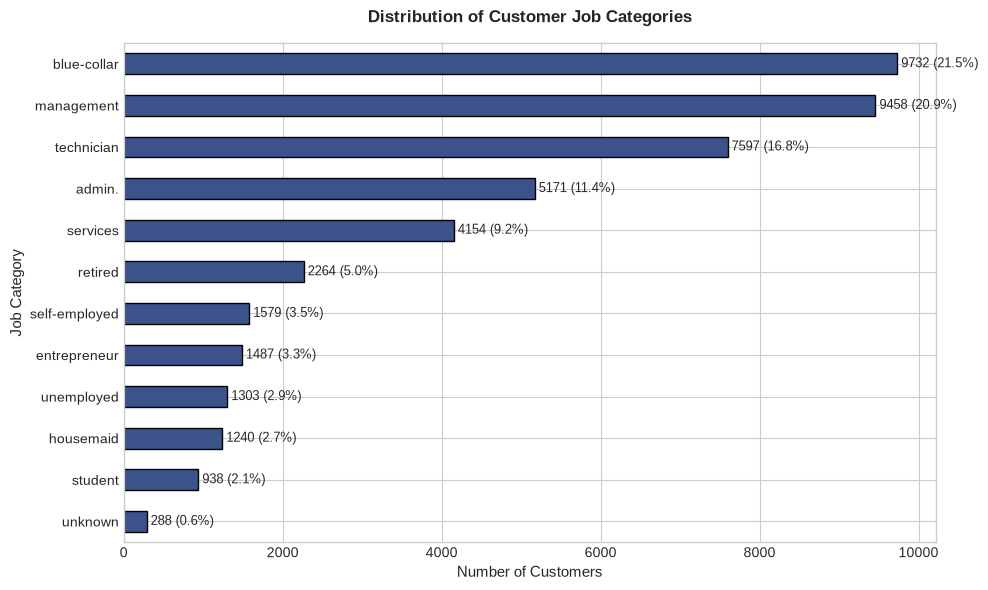

Saved plot: Lab3/outputs/bank_job_distribution.png


In [12]:
# 12. Job Category Distribution (Bank Marketing)
fig, ax = plt.subplots(figsize=(10, 6))

job_counts = df_bank['job'].value_counts().sort_values(ascending=True)
job_counts.plot(kind='barh', ax=ax, color='#3b528b', edgecolor='black')

ax.set_title("Distribution of Customer Job Categories", fontweight='bold', pad=15)
ax.set_xlabel("Number of Customers")
ax.set_ylabel("Job Category")

for idx, val in enumerate(job_counts):
    ax.annotate(f" {val} ({val/len(df_bank)*100:.1f}%)",
                (val, idx),
                va='center', fontsize=9)

plt.tight_layout()
fig_path = OUTPUT_DIR / "bank_job_distribution.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved plot: {fig_path}")

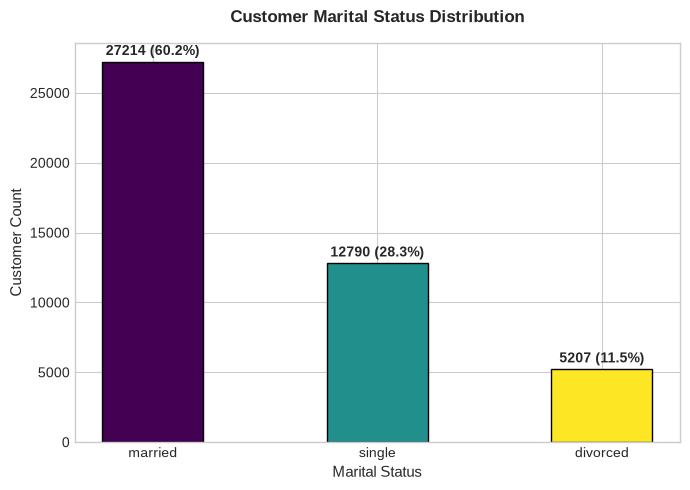

Saved plot: Lab3/outputs/bank_marital_status_distribution.png


In [13]:
# 13. Marital Status Distribution (Bank Marketing)
fig, ax = plt.subplots(figsize=(7, 5))

marital_counts = df_bank['marital'].value_counts()
colors = ['#440154', '#21908d', '#fde725']

ax.bar(marital_counts.index, marital_counts.values, color=colors, edgecolor='black', width=0.45)
ax.set_title("Customer Marital Status Distribution", fontweight='bold', pad=15)
ax.set_xlabel("Marital Status")
ax.set_ylabel("Customer Count")

for idx, val in enumerate(marital_counts.values):
    ax.annotate(f"{val} ({val/len(df_bank)*100:.1f}%)",
                (idx, val + 500),
                ha='center', fontweight='semibold')

plt.tight_layout()
fig_path = OUTPUT_DIR / "bank_marital_status_distribution.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved plot: {fig_path}")

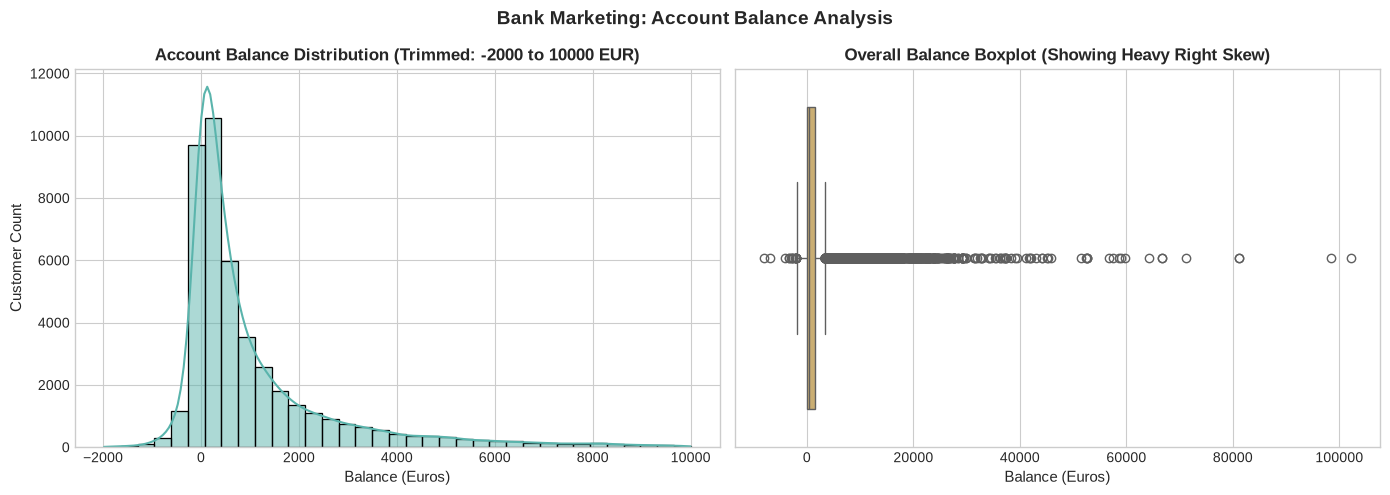

Saved plot: Lab3/outputs/bank_balance_distribution.png


In [14]:
# 14. Customer Account Balance Distribution (Bank Marketing)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Filter out extreme outliers for visualization clarity (e.g., -2000 to 10000 EUR)
filtered_balance = df_bank[(df_bank['balance'] >= -2000) & (df_bank['balance'] <= 10000)]['balance']

sns.histplot(filtered_balance, bins=35, kde=True, ax=ax1, color='#5ab4ac', edgecolor='black')
ax1.set_title("Account Balance Distribution (Trimmed: -2000 to 10000 EUR)", fontweight='bold')
ax1.set_xlabel("Balance (Euros)")
ax1.set_ylabel("Customer Count")

sns.boxplot(x=df_bank['balance'], ax=ax2, color='#d8b365')
ax2.set_title("Overall Balance Boxplot (Showing Heavy Right Skew)", fontweight='bold')
ax2.set_xlabel("Balance (Euros)")

plt.suptitle("Bank Marketing: Account Balance Analysis", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path = OUTPUT_DIR / "bank_balance_distribution.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved plot: {fig_path}")

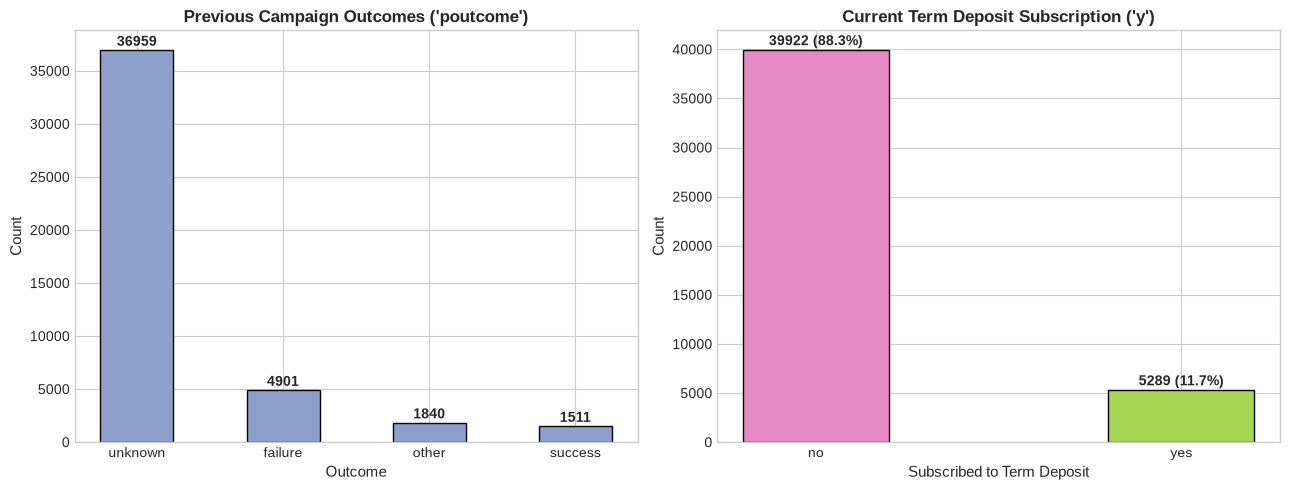

Saved plot: Lab3/outputs/bank_campaign_outcomes.png


In [15]:
# 15. Previous Campaign Outcomes and Current Subscription Target
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Outcome of previous marketing campaign
poutcome_counts = df_bank['poutcome'].value_counts()
ax1.bar(poutcome_counts.index, poutcome_counts.values, color='#8da0cb', edgecolor='black', width=0.5)
ax1.set_title("Previous Campaign Outcomes ('poutcome')", fontweight='bold')
ax1.set_xlabel("Outcome")
ax1.set_ylabel("Count")
for idx, val in enumerate(poutcome_counts.values):
    ax1.annotate(f"{val}", (idx, val + 400), ha='center', fontweight='semibold')

# Target variable 'y' (Term Deposit Subscription)
y_counts = df_bank['y'].value_counts()
ax2.bar(y_counts.index, y_counts.values, color=['#e78ac3', '#a6d854'], edgecolor='black', width=0.4)
ax2.set_title("Current Term Deposit Subscription ('y')", fontweight='bold')
ax2.set_xlabel("Subscribed to Term Deposit")
ax2.set_ylabel("Count")
for idx, val in enumerate(y_counts.values):
    pct = (val / len(df_bank)) * 100
    ax2.annotate(f"{val} ({pct:.1f}%)", (idx, val + 500), ha='center', fontweight='semibold')

plt.tight_layout()
fig_path = OUTPUT_DIR / "bank_campaign_outcomes.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved plot: {fig_path}")

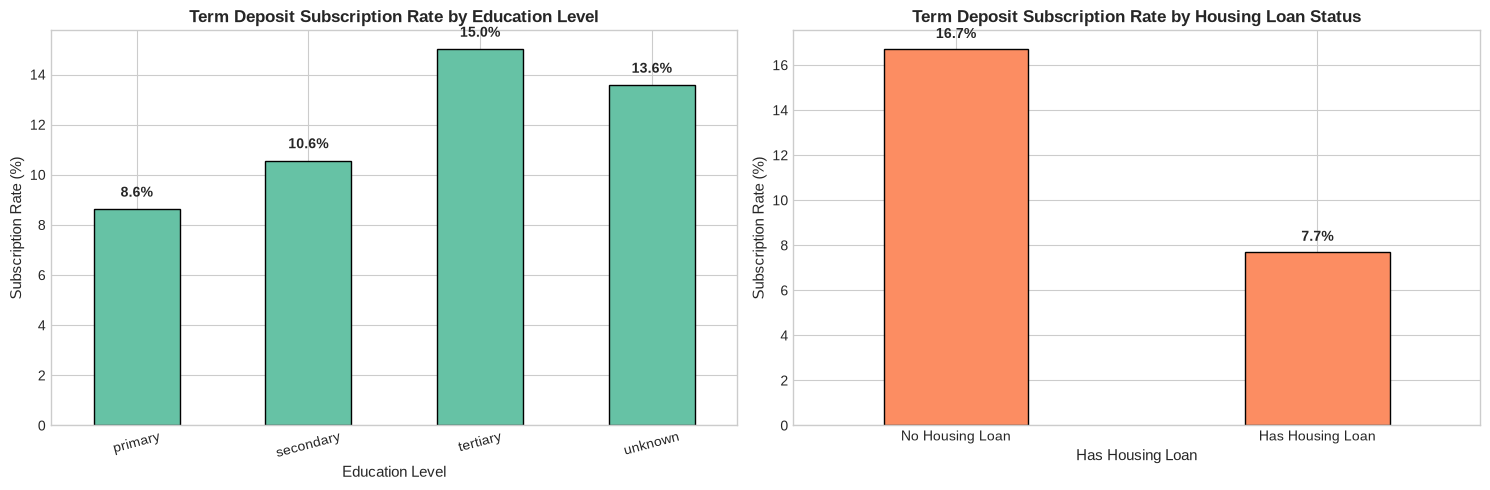

Saved plot: Lab3/outputs/bank_subscription_comparisons.png


In [16]:
# 16. Subscription Rate Comparisons across Key Demographics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Subscription rate by Education Level
edu_sub = pd.crosstab(df_bank['education'], df_bank['y'], normalize='index')['yes'] * 100
edu_sub.plot(kind='bar', ax=ax1, color='#66c2a5', edgecolor='black', width=0.5)
ax1.set_title("Term Deposit Subscription Rate by Education Level", fontweight='bold')
ax1.set_xlabel("Education Level")
ax1.set_ylabel("Subscription Rate (%)")
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=15)
for p in ax1.patches:
    ax1.annotate(f"{p.get_height():.1f}%",
                (p.get_x() + p.get_width() / 2, p.get_height() + 0.5),
                ha='center', fontweight='semibold')

# Subscription rate by Housing Loan Status
housing_sub = pd.crosstab(df_bank['housing'], df_bank['y'], normalize='index')['yes'] * 100
housing_sub.plot(kind='bar', ax=ax2, color='#fc8d62', edgecolor='black', width=0.4)
ax2.set_title("Term Deposit Subscription Rate by Housing Loan Status", fontweight='bold')
ax2.set_xlabel("Has Housing Loan")
ax2.set_ylabel("Subscription Rate (%)")
ax2.set_xticklabels(['No Housing Loan', 'Has Housing Loan'], rotation=0)
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.1f}%",
                (p.get_x() + p.get_width() / 2, p.get_height() + 0.5),
                ha='center', fontweight='semibold')

plt.tight_layout()
fig_path = OUTPUT_DIR / "bank_subscription_comparisons.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved plot: {fig_path}")